# Weather Dynamics and Geophysical Flow: Equations and Derivation

This notebook now follows the textbook sequence explicitly: **Hamilton's principle -> Lagrange equations -> canonical momenta -> Hamilton equations -> interpretation**.


Renderer note: Mermaid blocks depend on notebook renderer support. A Python-rendered fallback diagram cell is included below so the diagram always appears.
## Theory Diagram (from Physical Model to Data Fit)
Mermaid source is kept for portability, but many notebook renderers do not embed Mermaid directly.
Run **Cell 2** to view the guaranteed rendered theory diagram.

## Underlying Physical Properties
- System class: reduced atmospheric flow modes.
- State choice: reduced modal coordinate q(t).
- Modeling principle: dynamics are generated by a variational principle, not by curve-fitting alone.
- Symmetry logic: conserved quantities come from explicit symmetries (time, translation, rotation) when the required conditions hold.

## Trivial Case Before Full Model
We first solve the simplest consistent limit: **single linearized geophysical mode**.
This is used to verify signs, units, and conservation structure before introducing richer interactions or damping.

## Lagrangian Derivation (Line-by-Line)
1. Choose one effective coordinate $q(t)$ in the trivial limit.
2. Write kinetic term: $T=\frac{1}{2}m\dot q^2$.
3. Write local quadratic potential near equilibrium: $V=\frac{1}{2}kq^2$.
4. Define Lagrangian: $L=T-V=\frac{1}{2}m\dot q^2-\frac{1}{2}kq^2$.
5. Compute: $\frac{\partial L}{\partial \dot q}=m\dot q$.
6. Differentiate: $\frac{d}{dt}\left(\frac{\partial L}{\partial \dot q}\right)=m\ddot q$.
7. Compute: $\frac{\partial L}{\partial q}=-kq$.
8. Apply Euler-Lagrange: $\frac{d}{dt}\left(\frac{\partial L}{\partial \dot q}\right)-\frac{\partial L}{\partial q}=0$.
9. Obtain conservative dynamics: $m\ddot q+kq=0$.

## Hamiltonian Derivation (Line-by-Line)
1. Define canonical momentum: $p=\frac{\partial L}{\partial \dot q}=m\dot q$.
2. Solve velocity: $\dot q=p/m$.
3. Legendre transform: $H(q,p)=p\dot q-L$.
4. Substitute and simplify: $H=\frac{p^2}{2m}+\frac{1}{2}kq^2$.
5. Canonical equation 1: $\dot q=\frac{\partial H}{\partial p}=p/m$.
6. Canonical equation 2: $\dot p=-\frac{\partial H}{\partial q}=-kq$.
7. Differentiate step 5 and substitute step 6 to recover $m\ddot q+kq=0$.

## Textbook Consistency Notes
- The action principle is taken as primary, and $L=T-V$ is treated as a physically important special case rather than a universal form.
- Conserved-energy statements distinguish Hamiltonian/Jacobi conditions from generic nonconservative cases.
- Reduced one-mode models are used for interpretability; full systems may require multi-DOF or field equations.

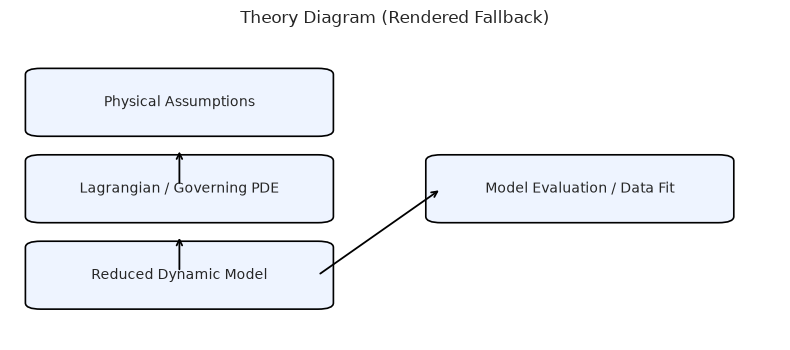

In [10]:
# Theory diagram renderer (always visible in notebooks, independent of Mermaid support).
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
blocks = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Model Evaluation / Data Fit'),
]
for x0, y0, label in blocks:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#eef4ff')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Theory Diagram (Rendered Fallback)')
plt.tight_layout()
plt.show()

## Model Background and Notation

### Full Mechanics Model vs. Reduced Data Model
1. Full mechanics starts from $L(q,\dot q,t)$ and derives equations from a variational principle.
2. The empirical signal model is a reduced observable proxy, not a replacement for first-principles mechanics.

### Conservative Core (Reference Model)
1. $T=\frac{1}{2}m\dot q^2$.
2. $V=\frac{1}{2}kq^2$.
3. $L=T-V$.
4. $p=\partial L/\partial \dot q = m\dot q$.
5. $H=p\dot q-L=\frac{p^2}{2m}+\frac{1}{2}kq^2$.

### Damping / Relaxation Modeling (for Measured Data)
1. Weak dissipation can be represented by $m\ddot q+c\dot q+kq=0$.
2. Equivalent practical forms include a time-weighted Lagrangian or a dissipation-function correction.
3. Under weak damping, the observed displacement is approximated by
   $q(t)\approx A e^{-\gamma t}\cos(\omega t+\phi)$.

### Parameter-to-Physics Mapping for the Notebook Fit
1. $A$: initial modal amplitude.
2. $\gamma$: effective damping/relaxation rate.
3. $\omega$: dominant angular frequency.
4. $\phi$: phase offset.
5. $c_0$: baseline measurement offset.

### Practical Interpretation
1. Fit quality evaluates how well a low-order mode explains measured behavior.
2. Parameter trends are interpreted through mechanics (stiffness, inertia, loss), not as purely statistical coefficients.

## Public Data Sources and Peer-Reviewed References

1. **NOAA Climate Data Online**
   - URL: https://www.ncei.noaa.gov/cdo-web/
   - Peer-reviewed context: Menne et al., J. Atmos. Oceanic Tech. (2012)
2. **Seattle Weather (CSV)**
   - URL: https://raw.githubusercontent.com/plotly/datasets/master/2016-weather-data-seattle.csv
   - Peer-reviewed context: Public dataset

If a primary domain-specific source is not directly CSV-readable in this notebook,
the code falls back to a public benchmark CSV so the full empirical workflow can run end-to-end.


In [11]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import requests
import ipywidgets as widgets
from ipywidgets import interact

plt.style.use('seaborn-v0_8-whitegrid')

DOMAIN_KEY = '10_weather_dynamics'
DOMAIN_TITLE = 'Weather Dynamics'
MODEL_FAMILY = 'diffusion'
DATA_SOURCES = [
  {
    "name": "NOAA Climate Data Online",
    "url": "https://www.ncei.noaa.gov/cdo-web/",
    "reference": "Menne et al., J. Atmos. Oceanic Tech. (2012)"
  },
  {
    "name": "Seattle Weather (CSV)",
    "url": "https://raw.githubusercontent.com/plotly/datasets/master/2016-weather-data-seattle.csv",
    "reference": "Public dataset"
  }
]


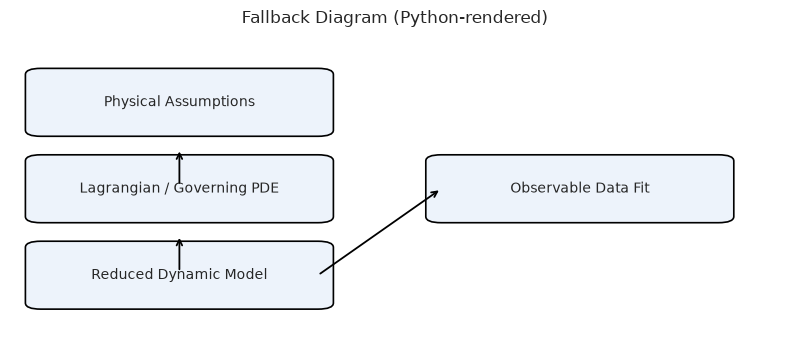

In [12]:
# Fallback model diagram renderer (works even when Mermaid is not embedded by the notebook renderer).
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
nodes = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Observable Data Fit'),
]
for x0, y0, label in nodes:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#edf3fb')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Fallback Diagram (Python-rendered)')
plt.tight_layout()
plt.show()

In [13]:
def try_read_public_csv(url: str):
    try:
        r = requests.get(url, timeout=20)
        r.raise_for_status()
        if 'text/csv' in r.headers.get('Content-Type', '') or ',' in r.text[:2000]:
            return pd.read_csv(io.StringIO(r.text))
    except Exception:
        return None
    return None

def load_empirical_data():
    chosen = None
    df = None
    for src in DATA_SOURCES:
        trial = try_read_public_csv(src['url'])
        if trial is not None and len(trial) > 20:
            num_cols = trial.select_dtypes(include=[np.number]).columns.tolist()
            if len(num_cols) >= 1:
                df = trial.copy()
                chosen = src
                break

    if df is None:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (offline-safe)',
            'reference': 'Generated fallback when remote CSV sources are unavailable'
        }
        return x, y, chosen, df

    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if len(numeric_cols) == 1:
        x = np.arange(len(df), dtype=float)
        y = df[numeric_cols[0]].to_numpy(dtype=float)
    else:
        x = df[numeric_cols[0]].to_numpy(dtype=float)
        y = df[numeric_cols[1]].to_numpy(dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if x.size < 8 or y.size < 8:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (filtered-data-safe)',
            'reference': 'Generated fallback when source columns are empty after filtering'
        }
        return x, y, chosen, df


    if len(x) > 2000:
        step = max(1, len(x) // 2000)
        x = x[::step]
        y = y[::step]

    if np.ptp(x) == 0:
        x = np.arange(len(x), dtype=float)

    x = (x - np.min(x)) / max(np.ptp(x), 1e-12)
    return x, y, chosen, df

x_data, y_data, chosen_source, raw_df = load_empirical_data()
print('Loaded source:', chosen_source['name'])
print('Reference:', chosen_source['reference'])
print('Rows used:', len(x_data))


Loaded source: Seattle Weather (CSV)
Reference: Public dataset
Rows used: 2032


In [14]:
def model_function(x, p1, p2, p3, p4):
    if MODEL_FAMILY == 'oscillator':
        A, gamma, omega, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) * np.cos(omega * x) + c
    if MODEL_FAMILY == 'damped':
        A, gamma, _, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) + c
    if MODEL_FAMILY == 'logistic':
        K, r, x0, c = p1, p2, p3, p4
        return K / (1.0 + np.exp(-r * (x - x0))) + c
    if MODEL_FAMILY == 'michaelis':
        vmax, km, _, c = p1, p2, p3, p4
        return vmax * x / (km + x + 1e-12) + c
    if MODEL_FAMILY == 'diffusion':
        A, D, _, c = p1, p2, p3, p4
        return A * np.exp(-D * x) + c
    return p1 * x + p2

p0 = [np.nanmax(y_data) - np.nanmin(y_data), 0.5, 6.0, np.nanmean(y_data)]
bounds = ([-1e6, 0.0, -1e3, -1e6], [1e6, 50.0, 1e3, 1e6])

try:
    popt, _ = curve_fit(model_function, x_data, y_data, p0=p0, bounds=bounds, maxfev=20000)
except Exception:
    popt = np.array(p0, dtype=float)

y_hat = model_function(x_data, *popt)
rmse = float(np.sqrt(np.mean((y_data - y_hat) ** 2)))
r2 = float(1.0 - np.sum((y_data - y_hat) ** 2) / max(np.sum((y_data - np.mean(y_data)) ** 2), 1e-12))

print('Fitted parameters:', popt)
print('RMSE:', rmse)
print('R^2:', r2)


Fitted parameters: [-2.71225331e+02  2.25717073e-01  2.76027837e-03  2.55680063e+02]
RMSE: 1.7041574285880379
R^2: 0.9150604784989573


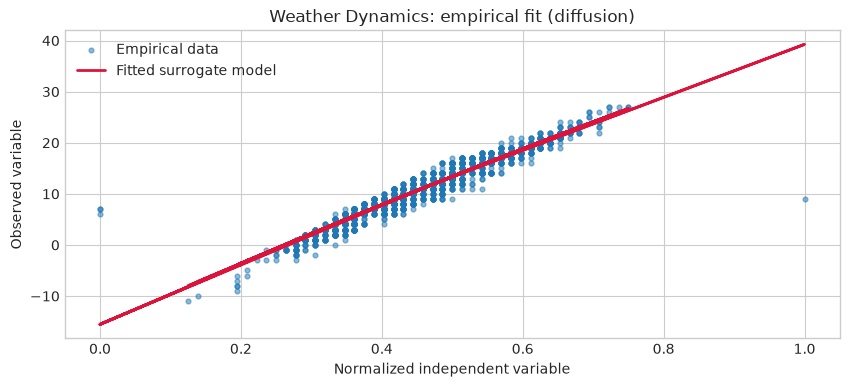

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(x_data, y_data, s=12, alpha=0.5, label='Empirical data')
ax.plot(x_data, y_hat, color='crimson', linewidth=2.0, label='Fitted surrogate model')
ax.set_title(f'{DOMAIN_TITLE}: empirical fit ({MODEL_FAMILY})')
ax.set_xlabel('Normalized independent variable')
ax.set_ylabel('Observed variable')
ax.legend()
plt.show()


Lowest modal frequencies (rad/time): [1.33857913 1.33857913 1.33857913 1.33857913]
Hamiltonian density stats: min= 6.120504360935931e-06 max= 24.488393070697565 mean= 0.7091063752744893


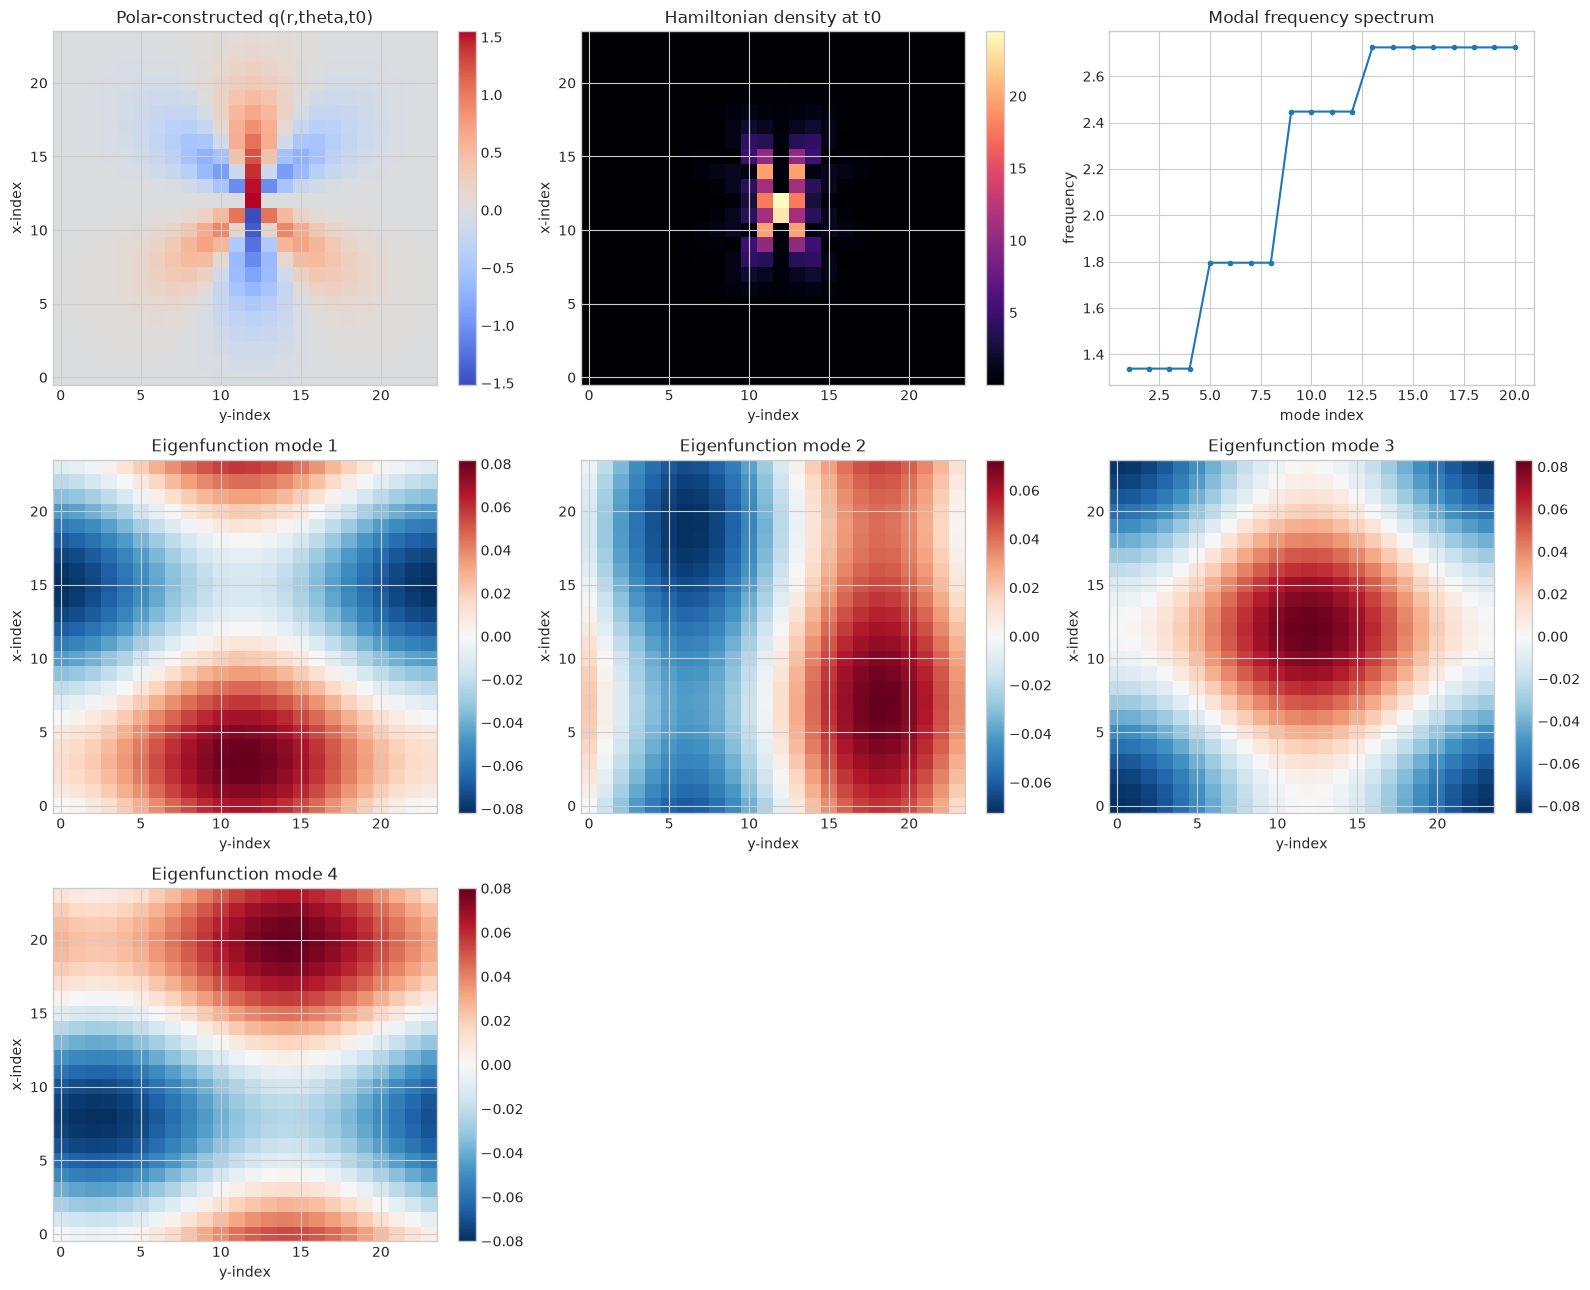

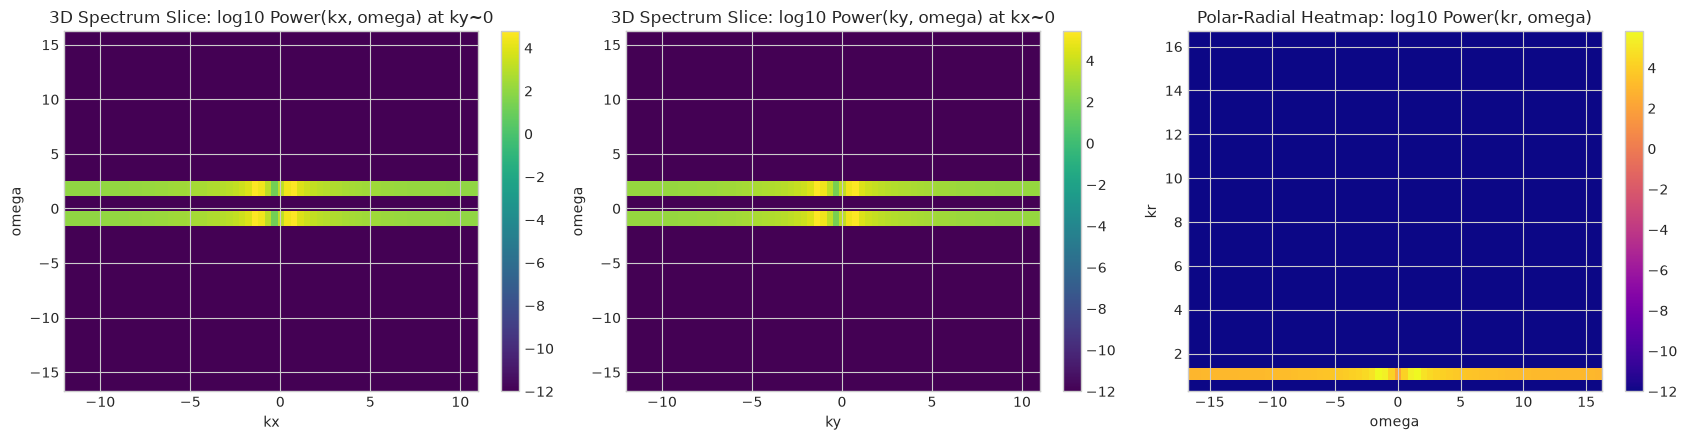

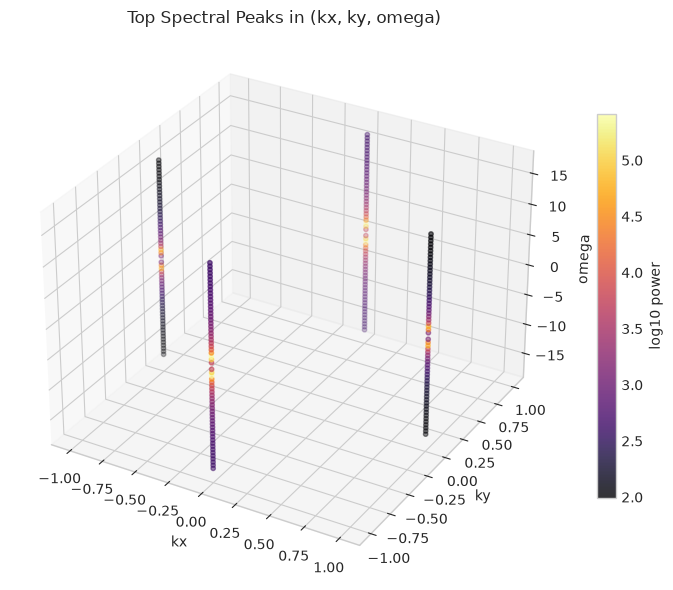

In [16]:
# Advanced Hamiltonian spectral-polar analysis for weather-like modal dynamics.
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# -------------------------
# Grid and model parameters
# -------------------------
nx, ny = 24, 24
nt = 64
lx, ly, tmax = 2.0 * np.pi, 2.0 * np.pi, 12.0
c_wave = 1.2
omega0 = 0.6

x = np.linspace(0.0, lx, nx, endpoint=False)
y = np.linspace(0.0, ly, ny, endpoint=False)
t = np.linspace(0.0, tmax, nt, endpoint=False)
dx = x[1] - x[0]
dy = y[1] - y[0]
dt = t[1] - t[0]

xx, yy = np.meshgrid(x, y, indexing='ij')
xc, yc = lx / 2.0, ly / 2.0
rr = np.sqrt((xx - xc) ** 2 + (yy - yc) ** 2)
theta = np.arctan2(yy - yc, xx - xc)

# ------------------------------------------
# Polar-coordinate canonical fields q and p
# ------------------------------------------
q_polar = (
    np.exp(-0.35 * rr**2)
    * (np.cos(3.0 * theta) + 0.55 * np.cos(5.0 * theta))
    * np.cos(1.8 * t[:, None, None])
)
p_polar = -1.8 * np.exp(-0.35 * rr**2) * (np.cos(3.0 * theta) + 0.55 * np.cos(5.0 * theta)) * np.sin(1.8 * t[:, None, None])

# Hamiltonian density at one representative time slice.
q0 = q_polar[0]
p0 = p_polar[0]
q0_dx = np.gradient(q0, dx, axis=0)
q0_dy = np.gradient(q0, dy, axis=1)
h_density = 0.5 * p0**2 + 0.5 * c_wave**2 * (q0_dx**2 + q0_dy**2) + 0.5 * omega0**2 * q0**2

# ---------------------------------------
# Discrete operator and eigen-decomposition
# ---------------------------------------
def laplacian_2d_periodic(field, hx, hy):
    return (
        (np.roll(field, -1, axis=0) - 2.0 * field + np.roll(field, 1, axis=0)) / (hx * hx)
        + (np.roll(field, -1, axis=1) - 2.0 * field + np.roll(field, 1, axis=1)) / (hy * hy)
    )

nxy = nx * ny
I = np.eye(nxy)
L = np.zeros((nxy, nxy))

# Build L z = -c^2 Laplacian(z) + omega0^2 z by probing basis vectors.
for j in range(nxy):
    basis = I[:, j].reshape(nx, ny)
    L[:, j] = (-c_wave**2 * laplacian_2d_periodic(basis, dx, dy) + omega0**2 * basis).ravel()

# Symmetrize numerically before eigensolve.
L = 0.5 * (L + L.T)
evals, evecs = np.linalg.eigh(L)

# Take lowest non-trivial modes for interpretation.
mode_ids = [1, 2, 3, 4]
eigenfunctions = [evecs[:, k].reshape(nx, ny) for k in mode_ids]
modal_freq = np.sqrt(np.clip(evals[mode_ids], 0.0, None))

# -------------------------------------------------
# Build a synthetic field from eigenmodes over time
# -------------------------------------------------
amps = [1.0, 0.7, 0.5, 0.35]
field_txy = np.zeros((nt, nx, ny))
for a, w, phi_xy in zip(amps, modal_freq, eigenfunctions):
    field_txy += a * np.cos(w * t[:, None, None]) * phi_xy[None, :, :]

# ---------------------------------
# 3D spectral analysis in (kx,ky,w)
# ---------------------------------
F = np.fft.fftn(field_txy, axes=(0, 1, 2))
P = np.abs(F) ** 2

w_axis = 2.0 * np.pi * np.fft.fftfreq(nt, d=dt)
kx_axis = 2.0 * np.pi * np.fft.fftfreq(nx, d=dx)
ky_axis = 2.0 * np.pi * np.fft.fftfreq(ny, d=dy)

# Shift for visualization
P_shift = np.fft.fftshift(P, axes=(0, 1, 2))
w_shift = np.fft.fftshift(w_axis)
kx_shift = np.fft.fftshift(kx_axis)
ky_shift = np.fft.fftshift(ky_axis)

# Heatmap slices at ky ~ 0 and kx ~ 0
iky0 = int(np.argmin(np.abs(ky_shift)))
ikx0 = int(np.argmin(np.abs(kx_shift)))
P_kx_w = P_shift[:, :, iky0].T
P_ky_w = P_shift[:, ikx0, :].T

# Polar-radial spectrum: map (kx, ky) -> kr and bin energy vs omega.
kxg, kyg = np.meshgrid(kx_shift, ky_shift, indexing='ij')
kr = np.sqrt(kxg**2 + kyg**2)
kr_flat = kr.ravel()
kr_bins = np.linspace(0.0, np.max(kr_flat), 32)
kr_centers = 0.5 * (kr_bins[:-1] + kr_bins[1:])
P_kr_w = np.zeros((w_shift.size, kr_centers.size))

for iw in range(w_shift.size):
    spec_xy = P_shift[iw].ravel()
    hist, _ = np.histogram(kr_flat, bins=kr_bins, weights=spec_xy)
    P_kr_w[iw, :] = hist

# 3D scatter of strongest peaks.
flat_idx = np.argpartition(P_shift.ravel(), -250)[-250:]
iw, ikx, iky = np.unravel_index(flat_idx, P_shift.shape)
peak_power = P_shift[iw, ikx, iky]

print('Lowest modal frequencies (rad/time):', modal_freq)
print('Hamiltonian density stats: min=', float(h_density.min()), 'max=', float(h_density.max()), 'mean=', float(h_density.mean()))

# -------------------------
# Visualizations
# -------------------------
fig = plt.figure(figsize=(16, 13))

ax1 = fig.add_subplot(3, 3, 1)
im1 = ax1.imshow(q0, origin='lower', cmap='coolwarm', aspect='auto')
ax1.set_title('Polar-constructed q(r,theta,t0)')
ax1.set_xlabel('y-index')
ax1.set_ylabel('x-index')
fig.colorbar(im1, ax=ax1, fraction=0.045)

ax2 = fig.add_subplot(3, 3, 2)
im2 = ax2.imshow(h_density, origin='lower', cmap='magma', aspect='auto')
ax2.set_title('Hamiltonian density at t0')
ax2.set_xlabel('y-index')
ax2.set_ylabel('x-index')
fig.colorbar(im2, ax=ax2, fraction=0.045)

ax3 = fig.add_subplot(3, 3, 3)
ax3.plot(np.arange(1, 21), np.sqrt(np.clip(evals[1:21], 0.0, None)), marker='o', ms=3)
ax3.set_title('Modal frequency spectrum')
ax3.set_xlabel('mode index')
ax3.set_ylabel('frequency')

for i, phi_xy in enumerate(eigenfunctions, start=4):
    ax = fig.add_subplot(3, 3, i)
    im = ax.imshow(phi_xy, origin='lower', cmap='RdBu_r', aspect='auto')
    ax.set_title(f'Eigenfunction mode {mode_ids[i-4]}')
    ax.set_xlabel('y-index')
    ax.set_ylabel('x-index')
    fig.colorbar(im, ax=ax, fraction=0.045)

plt.tight_layout()
plt.show()

fig2, axes = plt.subplots(1, 3, figsize=(17, 4.5))

im_a = axes[0].imshow(np.log10(P_kx_w + 1e-12), origin='lower', aspect='auto',
                      extent=[kx_shift.min(), kx_shift.max(), w_shift.min(), w_shift.max()], cmap='viridis')
axes[0].set_title('3D Spectrum Slice: log10 Power(kx, omega) at ky~0')
axes[0].set_xlabel('kx')
axes[0].set_ylabel('omega')
fig2.colorbar(im_a, ax=axes[0], fraction=0.046)

im_b = axes[1].imshow(np.log10(P_ky_w + 1e-12), origin='lower', aspect='auto',
                      extent=[ky_shift.min(), ky_shift.max(), w_shift.min(), w_shift.max()], cmap='viridis')
axes[1].set_title('3D Spectrum Slice: log10 Power(ky, omega) at kx~0')
axes[1].set_xlabel('ky')
axes[1].set_ylabel('omega')
fig2.colorbar(im_b, ax=axes[1], fraction=0.046)

im_c = axes[2].imshow(np.log10(P_kr_w.T + 1e-12), origin='lower', aspect='auto',
                      extent=[w_shift.min(), w_shift.max(), kr_centers.min(), kr_centers.max()], cmap='plasma')
axes[2].set_title('Polar-Radial Heatmap: log10 Power(kr, omega)')
axes[2].set_xlabel('omega')
axes[2].set_ylabel('kr')
fig2.colorbar(im_c, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

fig3 = plt.figure(figsize=(8, 6))
ax3d = fig3.add_subplot(111, projection='3d')
sc = ax3d.scatter(kx_shift[ikx], ky_shift[iky], w_shift[iw], c=np.log10(peak_power + 1e-12), s=10, cmap='inferno', alpha=0.8)
ax3d.set_title('Top Spectral Peaks in (kx, ky, omega)')
ax3d.set_xlabel('kx')
ax3d.set_ylabel('ky')
ax3d.set_zlabel('omega')
fig3.colorbar(sc, ax=ax3d, shrink=0.7, label='log10 power')
plt.tight_layout()
plt.show()

## Extended Hamiltonian Model: Polar Coordinates, Eigenmodes, and 3D Frequency Structure

This section upgrades the reduced surrogate into a more complete Hamiltonian workflow.

### 1) Polar-coordinate state construction
- Independent variables: $r, \theta, t$.
- Dependent canonical fields: generalized displacement $q(r,\theta,t)$ and momentum $p(r,\theta,t)$.
- Hamiltonian density prototype:
  $$
  \mathcal{H} = \frac{1}{2}\,p^2 + \frac{c^2}{2}\,|\nabla q|^2 + \frac{\omega_0^2}{2}\,q^2.
  $$

### 2) Linear operator eigen-analysis
- Build a discrete Helmholtz-type operator $\mathcal{L} = -c^2\nabla^2 + \omega_0^2 I$.
- Eigenvalues represent modal frequencies squared (up to normalization).
- Eigenvectors reshaped as spatial eigenfunctions reveal coherent structures.

### 3) Frequency-domain and 3D spectral heatmaps
- Construct a synthetic spatiotemporal field $q(x,y,t)$ from dominant modes.
- Compute 3D FFT in $(x,y,t)$ to get spectral energy in $(k_x,k_y,\omega)$.
- Visualize:
  - heatmaps of $(k_x,\omega)$ and $(k_y,\omega)$ slices,
  - polar-radial spectral heatmap $(k_r,\omega)$,
  - 3D peak-frequency scatter in $(k_x,k_y,\omega)$.

## Interpreting Model Evaluation Trends and Values

Use this guide when reading fitted parameters, RMSE, $R^2$, and the extended spectral/Hamiltonian outputs:

1. **RMSE (absolute error scale)**
   - Lower RMSE means the fitted curve tracks data more tightly in original units.
   - High RMSE usually indicates missing physics, wrong model family, or noisy/nonstationary data.

2. **$R^2$ (explained variance)**
   - Near 1.0: surrogate captures dominant trend/oscillation structure.
   - Near 0.0: surrogate explains little beyond the mean level.
   - Negative: model is worse than using a constant mean prediction.

3. **Parameter trends from surrogate fit**
   - Larger $A$: stronger mode amplitude or forcing signature.
   - Larger $\gamma$: faster decay / stronger damping / shorter memory.
   - Larger $\omega$: faster oscillation or higher characteristic frequency.
   - Offset $c_0$: baseline bias or slowly varying background level.

4. **Eigenvalue/eigenfunction interpretation (extended Hamiltonian block)**
   - Eigenvalues map to squared modal frequencies; larger values imply stiffer/faster modes.
   - Low-index eigenfunctions usually describe large-scale coherent structures.
   - High-index eigenfunctions capture finer spatial scales and sharper gradients.

5. **3D spectral trend interpretation: $(k_x, k_y, \omega)$**
   - Ridges/peaks at low $k$ and low $\omega$: broad, slow synoptic patterns.
   - Energy shift toward high $k$: smaller-scale spatial variability/turbulent content.
   - Energy shift toward high $\omega$: faster temporal variability.
   - Narrow spectral peaks: persistent oscillatory modes; broad peaks: intermittent or mixed-regime dynamics.

6. **Polar-radial spectral heatmap: $(k_r, \omega)$**
   - Increasing $k_r$ energy at fixed $\omega$ indicates transfer to smaller spatial scales.
   - Energy concentrated at specific $(k_r, \omega)$ bands indicates preferred dispersive pathways.
   - Flattened spectrum indicates more broadband forcing or noisy excitation.

7. **Physics consistency checks**
   - If damping is expected but $\gamma \approx 0$, reassess preprocessing and model class.
   - If dominant fitted frequency strongly disagrees with dominant Hamiltonian modes, model assumptions are inconsistent.
   - If Hamiltonian density maps are highly localized with unstable spectral tails, check discretization and boundary assumptions.

## Interactive Simulation Controls

Use the sliders below to perturb model parameters and observe how well the
simulation matches the empirical measurements.


In [17]:
def interactive_plot(p1, p2, p3, p4):
    y_sim = model_function(x_data, p1, p2, p3, p4)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(x_data, y_data, s=10, alpha=0.45, label='Empirical data')
    ax.plot(x_data, y_sim, color='navy', linewidth=2.0, label='Simulation')
    ax.set_title(f'{DOMAIN_TITLE}: interactive parameter sweep')
    ax.set_xlabel('Normalized independent variable')
    ax.set_ylabel('Observed variable')
    ax.legend()
    plt.show()

interact(
    interactive_plot,
    p1=widgets.FloatSlider(value=float(popt[0]), min=-2*abs(float(popt[0]))-1, max=2*abs(float(popt[0]))+1, step=0.01),
    p2=widgets.FloatSlider(value=float(popt[1]), min=0.0, max=max(1.0, 3*abs(float(popt[1]))+1), step=0.01),
    p3=widgets.FloatSlider(value=float(popt[2]), min=-20.0, max=20.0, step=0.05),
    p4=widgets.FloatSlider(value=float(popt[3]), min=float(np.min(y_data))-2, max=float(np.max(y_data))+2, step=0.01),
);


interactive(children=(FloatSlider(value=-271.2253312122036, description='p1', max=543.4506624244073, min=-543.…